# Confidence: how reliably does one item bring another?

**Week 4, Wednesday, chapter 2 of the concept block.** The topic, in the curriculum's words: *Support, confidence and lift, derived by counting*.
The examples are invented for this chapter, small enough to count by hand: every number below is counted from a table in `data/`, and the code only confirms the count.

**Who needs the answer.** The canteen manager, who must decide which item the combo card is printed beside: a card aimed at the wrong buyer reads well and sells nothing.

**The questions on the way.** What does "of those" count? Does direction matter? How far can it swing? What can confidence not say?

In [1]:
def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)
    assert ok, name
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})
import pandas as pd
from collections import Counter
from itertools import combinations

lines = pd.read_csv("../data/C2_W04_D03_canteen_order_lines_STUDENT.csv")
listed = lines.groupby("order_id").item.apply(list)      # the items in the order the bill lists them
baskets = listed.apply(set)                               # one set of items per order
n = len(baskets)
print("A hostel canteen's twelve lunch orders, invented for the concept chapters:")
for order_id, held in listed.items():
    print(f"  {order_id}: {', '.join(held)}")


def has(item):
    """True for every order that holds the item."""
    return baskets.apply(lambda b: item in b)


check("twelve orders and 33 order lines", n == 12 and len(lines) == 33)

A hostel canteen's twelve lunch orders, invented for the concept chapters:
  T01: dal rice, papad, chaas
  T02: dal rice, papad, chaas
  T03: dal rice, papad, chaas
  T04: dal rice, sabzi, chaas
  T05: dal rice, chaas
  T06: dal rice, curd, chaas
  T07: roti, papad, pickle
  T08: papad, pickle
  T09: roti, sabzi, chaas
  T10: roti, sabzi, chaas
  T11: roti, sabzi, chaas
  T12: gulab jamun, curd
PASS twelve orders and 33 order lines


## Dal rice to papad reads 0.50: what does papad to dal rice read?

**Confidence** from A to B shrinks the world to the baskets that hold A, then asks how
many of those also hold B. It is a rate inside a segment, as Week 1 Tuesday's rates were,
and its denominator is the segment's size. Dal rice is in 6 orders, papad in 5, both in 3.

**Predict before you run.** What is the confidence from papad to dal rice?

a) 0.50, since confidence reads the same both ways, like support.
b) 0.60, since three of papad's five orders hold dal rice.
c) 0.25, since three of all twelve orders hold both.
d) 1.00, since every papad order holds dal rice.

In [2]:
dal, papad = has("dal rice"), has("papad")
both = (dal & papad).sum()
print(f"dal rice in {dal.sum()} orders, papad in {papad.sum()}, both in {both}")
print(f"dal rice to papad: {both} / {dal.sum()} = {both / dal.sum():.2f}")
print(f"papad to dal rice: {both} / {papad.sum()} = {both / papad.sum():.2f}")
check("dal rice to papad reads 0.50", both / dal.sum() == 0.5)
check("papad to dal rice reads 0.60", both / papad.sum() == 0.6)

dal rice in 6 orders, papad in 5, both in 3
dal rice to papad: 3 / 6 = 0.50
papad to dal rice: 3 / 5 = 0.60
PASS dal rice to papad reads 0.50
PASS papad to dal rice reads 0.60


**What happened.** The answer is b. From dal rice the world shrinks to its 6 orders and 3
hold papad, 0.50; from papad it shrinks to 5 orders and
the same 3 hold dal rice, 0.60. Option c is support,
which divides by all twelve. **The trap** is reporting one direction's number for the
other, which aims the combo card at the wrong buyer. The picture shrinks the world twice.

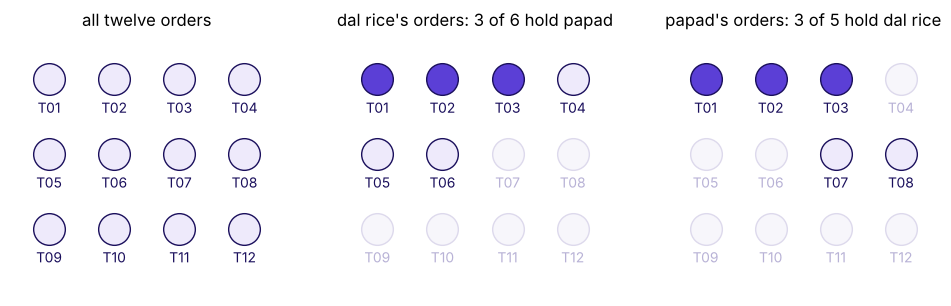

In [3]:
ids = list(baskets.index)
xy = {o: (i % 4, -(i // 4)) for i, o in enumerate(ids)}
views = [("all twelve orders", set(ids), set()),
         ("dal rice's orders: 3 of 6 hold papad", set(baskets[dal].index), set(baskets[dal & papad].index)),
         ("papad's orders: 3 of 5 hold dal rice", set(baskets[papad].index), set(baskets[dal & papad].index))]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, (title, world, hit) in zip(axes, views):
    for o, (x, y) in xy.items():
        inside = o in world
        face = "#5B3FD6" if o in hit else ("#EEEAFB" if inside else "#F7F6FB")
        ax.scatter(x, y, s=520, color=face, edgecolor="#1A0F5C" if inside else "#DDD9EC", zorder=2)
        ax.text(x, y - 0.45, o, ha="center", fontsize=10, color="#1A0F5C" if inside else "#B8B2D6")
    ax.set_title(title, fontsize=12)
    ax.set_xlim(-0.6, 3.6)
    ax.set_ylim(-2.9, 0.6)
    ax.axis("off")
plt.show()

## How far apart can the two directions sit?

Every pair has two confidences, one from each side. The cell computes both for the 13
pairs found in the twelve orders and plots one against the other: a point on the diagonal
reads the same both ways.

       a           b  both  a_to_b  b_to_a
   chaas    dal rice     6    0.67    1.00
   chaas       papad     3    0.33    0.60
dal rice       papad     3    0.50    0.60
   chaas       sabzi     4    0.44    1.00
dal rice       sabzi     1    0.17    0.25
   chaas        curd     1    0.11    0.50
    curd    dal rice     1    0.50    0.17
   papad      pickle     2    0.40    1.00
   papad        roti     1    0.20    0.25
  pickle        roti     1    0.50    0.25
   chaas        roti     3    0.33    0.75
    roti       sabzi     3    0.75    0.75
    curd gulab jamun     1    0.50    1.00


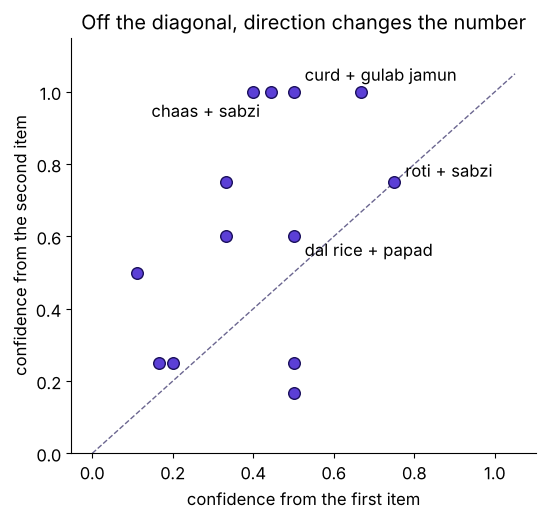

PASS 13 pairs, each counted once
PASS gulab jamun to curd 1.00, curd to gulab jamun 0.50
PASS roti and sabzi read 0.75 both ways


In [4]:
single = Counter(x for b in baskets for x in b)
pair_count = Counter(p for b in baskets for p in combinations(sorted(b), 2))
table = pd.DataFrame([{"a": a, "b": b, "both": k, "a_to_b": k / single[a], "b_to_a": k / single[b]}
                      for (a, b), k in pair_count.items()])
print(table.round(2).to_string(index=False))
fig, ax = plt.subplots(figsize=(6, 5.4))
ax.plot([0, 1.05], [0, 1.05], color="#6B6690", ls="--", lw=1)
ax.scatter(table.a_to_b, table.b_to_a, s=70, color="#5B3FD6", edgecolor="#1A0F5C", zorder=3)
place = {("curd", "gulab jamun"): (8, 8, "left"), ("chaas", "sabzi"): (-8, -18, "right"),
         ("roti", "sabzi"): (8, 4, "left"), ("dal rice", "papad"): (8, -14, "left")}
for r in table.itertuples():
    if (r.a, r.b) in place:
        dx, dy, ha = place[(r.a, r.b)]
        ax.annotate(f"{r.a} + {r.b}", (r.a_to_b, r.b_to_a), xytext=(dx, dy), textcoords="offset points", ha=ha)
ax.set_ylim(0, 1.15)
ax.set_xlabel("confidence from the first item")
ax.set_ylabel("confidence from the second item")
ax.set_title("Off the diagonal, direction changes the number")
plt.show()
gc = table[(table.a == "curd") & (table.b == "gulab jamun")].iloc[0]
rs = table[(table.a == "roti") & (table.b == "sabzi")].iloc[0]
check("13 pairs, each counted once", len(table) == 13)
check("gulab jamun to curd 1.00, curd to gulab jamun 0.50", (gc.b_to_a, gc.a_to_b) == (1.0, 0.5))
check("roti and sabzi read 0.75 both ways", rs.a_to_b == rs.b_to_a == 0.75)

## When do the two directions agree?

The formula, named last: confidence from A to B is the baskets holding both over the
baskets holding A. Both directions share the top line and differ only in the bottom one,
so they agree only when the two items sit in the same number of baskets, as roti and
sabzi do, 4 each. Sabzi to chaas reads 1.00, since every
sabzi order holds chaas; chaas to sabzi reads 0.44: the
same four orders, two sentences.

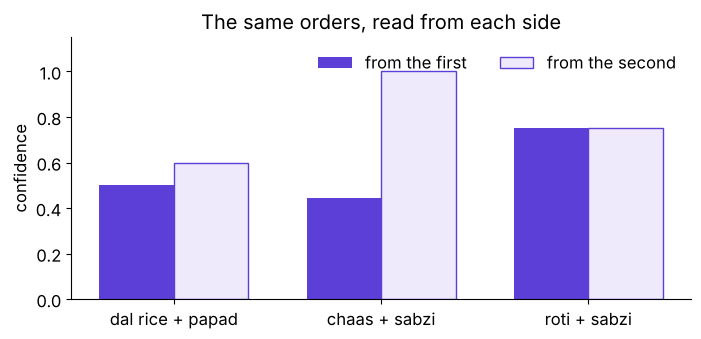

PASS for every pair, the two directions differ by the ratio of the items' counts


In [5]:
ratio_ok = all(abs(r.a_to_b / r.b_to_a - single[r.b] / single[r.a]) < 1e-9 for r in table.itertuples())
show = [("dal rice", "papad"), ("chaas", "sabzi"), ("roti", "sabzi")]
fig, ax = plt.subplots(figsize=(8, 3.4))
for i, (a, b) in enumerate(show):
    r = table[(table.a == a) & (table.b == b)].iloc[0]
    ax.bar(i - 0.18, r.a_to_b, 0.36, color="#5B3FD6", label="from the first" if i == 0 else None)
    ax.bar(i + 0.18, r.b_to_a, 0.36, color="#EEEAFB", edgecolor="#5B3FD6",
           label="from the second" if i == 0 else None)
ax.set_xticks(range(len(show)), [f"{a} + {b}" for a, b in show])
ax.set_ylim(0, 1.15)
ax.set_ylabel("confidence")
ax.legend(frameon=False, ncol=2)
ax.set_title("The same orders, read from each side")
plt.show()
check("for every pair, the two directions differ by the ratio of the items' counts", ratio_ok)

### Your turn: what do chaas to dal rice and dal rice to chaas read?

In the empty cell below, compute both directions for dal rice and chaas with `has()` and
store them as `chaas_to_dal` and `dal_to_chaas`. Then run the check under it.

In [6]:
both_dc = (has("dal rice") & has("chaas")).sum()
reference = (both_dc / has("chaas").sum(), both_dc / has("dal rice").sum())
mine = (globals().get("chaas_to_dal"), globals().get("dal_to_chaas"))
print(f"reference: chaas to dal rice {reference[0]:.2f}, dal rice to chaas {reference[1]:.2f}")
check("chaas to dal rice 0.67 and dal rice to chaas 1.00", (round(reference[0], 2), reference[1]) == (0.67, 1.0))
if None not in mine:
    check("your two confidences match the reference",
          all(abs(m - r) < 1e-9 for m, r in zip(mine, reference)))

reference: chaas to dal rice 0.67, dal rice to chaas 1.00
PASS chaas to dal rice 0.67 and dal rice to chaas 1.00


## What should you keep from chapter 2?

- Confidence from A to B is the baskets holding both over the baskets holding A.
- It is written with its direction, since its denominator is A's basket count: papad to
  dal rice 0.60, dal rice to papad
  0.50.
- The two directions agree only when the two items sit in the same number of baskets.
- Confidence alone never says whether a pair is special, since it ignores how common B is
  anyway: dal rice to chaas reads 1.00, and chaas is in
  9 of the twelve orders. Notebook 03 asks what chance
  alone would give.

**In the interview.** "What is confidence, and why does the direction matter?" Both over
A, so A to B and B to A divide by different baskets. Chapter 7 reads bread to milk on
Instamart's twelve carts.